In [7]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "mc_maze")

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(
        f"  {param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")
remove_pruned_trial_folders(study, RESULTS_PATH)

## Analysis

In [9]:
from src.models.mtf_model import MTFModel
from src.main import init_dataset

In [10]:
trial = get_trial_by_number(study.trials, 23)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)

params_ldim=209_dim_forcing=10_relu=20_mar=4_enc_lr=0p00_dec_lr=0p01_dsr_lr=0p00_gtf=0p05_gtf_gamma=0p93_aent=8p45_adsr=65p13_ac=0p08_ar=0p28_asc=0p00_alpha_mar=0p00


In [12]:
device = tc.device("cpu")
run = "001"

# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)


parameters = json.load(open(f"{run_path}/config.json"))
dataset = init_dataset(parameters, device)
model = MTFModel(dataset, model_path=run_path, device=device, current_epoch=2400)

# load test set
measurement2_go_cues = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/externals/go_cue_trials.pkl", allow_pickle=True)
measurement2_target_position = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/externals/target_position_trials.pkl", allow_pickle=True)
measurement2_spike_trials = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/observations/1_spikes_trials.pkl", allow_pickle=True)
measurement2_hand_position_trials = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/observations/2_hand_position_trials.pkl", allow_pickle=True)
measurement2_eye_position_trials = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/observations/3_eye_position_trials.pkl", allow_pickle=True)

externals_test = [tc.tensor(np.stack([measurement2_go_cues[time_series_index],
                                     measurement2_target_position[time_series_index][:, 0],
                                     measurement2_target_position[time_series_index][:, 1]], axis=1)).float() for time_series_index in range(len(measurement2_go_cues))]
observations_test = [tc.tensor(np.concatenate([measurement2_spike_trials[time_series_index],
                                              measurement2_hand_position_trials[time_series_index],
                                              measurement2_eye_position_trials[time_series_index]], axis=1)).float() for time_series_index in range(len(measurement2_spike_trials))]

Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230


In [ ]:
trajectories_train = []
trajectories_val = []
trajectories_test = []
latent_trajectories_test = []
encoded_trajectories_test = []

for time_series_index in range(len(dataset.evaluator_train_samples)):
    observations_train = dataset.evaluator_train_samples[time_series_index].input
    externals_train = dataset.evaluator_train_samples[time_series_index].external

    trajectory = model.generate_free_trajectory(
        observations_train,
        tc.tensor(range(1)).to(device),  # One trajectory per subject
        0,
        external_inputs=externals_train,
        use_expected_output=True,
    )[2].detach().cpu()
    trajectories_train.append(trajectory)

for time_series_index in range(len(dataset.evaluator_test_samples)):
    observations_val = dataset.evaluator_test_samples[time_series_index].input
    externals_val = dataset.evaluator_test_samples[time_series_index].external

    trajectory = model.generate_free_trajectory(
        observations_val,
        tc.tensor(range(1)).to(device),  # One trajectory per subject
        0,
        external_inputs=externals_val,
        use_expected_output=True,
    )[2].detach().cpu()
    trajectories_val.append(trajectory)


for time_series_index in range(min(50, len(measurement2_eye_position_trials))):
    latent_trajectory, encoded_trajectory, trajectory = model.generate_free_trajectory(
        observations_test[time_series_index],
        tc.tensor(range(1)).to(device),  # One trajectory per subject
        0,
        # padd externals with zeros
        external_inputs=tc.cat([externals_test[time_series_index], tc.zeros(200, 3)], dim=0),
        use_expected_output=True,
    )[:3]

    trajectories_test.append(trajectory.detach().cpu())
    latent_trajectories_test.append(latent_trajectory.detach().cpu())
    encoded_trajectories_test.append(encoded_trajectory.detach().cpu())

In [15]:
from src.evaluation.metrics.spike_stats import mean_spike_rate_nmse
print("Train set results:")
for time_series_index in range(len(dataset.evaluator_train_samples)):
    trajectory = trajectories_train[time_series_index]
    observations_train = dataset.evaluator_train_samples[time_series_index].input

    # compute mse of last 4 dimensions
    mse = nn.MSELoss()(trajectory[:, -4:], observations_train[:, -4:]).item()
    nmse = mean_spike_rate_nmse(
        trajectory[:, :182], observations_train[:, :182])
    print(
        f"MSE = {mse:.4f},", f"NMSE= {nmse:.4f}")

print("\nValidation set results:")
for time_series_index in range(len(dataset.evaluator_test_samples)):
    trajectory = trajectories_val[time_series_index]
    observations_val = dataset.evaluator_test_samples[time_series_index].input

    # compute mse of last 4 dimensions
    mse = nn.MSELoss()(trajectory[:, -4:], observations_val[:, -4:]).item()
    nmse = mean_spike_rate_nmse(trajectory[:, :182], observations_val[:, :182])
    print(
        f"MSE = {mse:.4f},", f"NMSE= {nmse:.4f}")

print("\nTest set results:")
test_mse = []
test_nmse = []
a = []
b = []
for time_series_index in range(len(trajectories_test)):
    trajectory = trajectories_test[time_series_index][:observations_test[time_series_index].shape[0]]

    # compute mse of last 4 dimensions
    mse = nn.MSELoss()(
        trajectory[:, -4:], observations_test[time_series_index][:, -4:]).item()
    nmse = mean_spike_rate_nmse(
        trajectory[:, :182], observations_test[time_series_index][:, :182])
    
    test_mse.append(mse)
    test_nmse.append(nmse)
print(
        f"Average MSE = {np.mean(test_mse):.4f} ± {np.std(test_mse):.4f},", f"Average NMSE= {np.mean(test_nmse):.4f} ± {np.std(test_nmse):.4f}")

Train set results:
MSE = 0.0263, NMSE= 0.1684
MSE = 0.0263, NMSE= 0.1253
MSE = 0.0129, NMSE= 0.1316
MSE = 0.0101, NMSE= 0.1978
MSE = 0.0465, NMSE= 0.1232

Validation set results:
MSE = 0.0174, NMSE= 0.1269
MSE = 0.0126, NMSE= 0.1575
MSE = 0.0156, NMSE= 0.1027
MSE = 0.0102, NMSE= 0.1195
MSE = 0.0215, NMSE= 0.3060

Test set results:
Average MSE = 0.0391 ± 0.0683, Average NMSE= 0.1686 ± 0.0438


In [22]:
best_dims = []
idx = tc.randint(0, len(observations_test), (1,)).item()
print(idx)
for dim in range(182):
    trajectories = model.generate_free_trajectory(
        observations_test[idx],
        tc.tensor(range(1)).to(device),  # One trajectory per subject
        0,
        num_samples=20,
        external_inputs=externals_test[idx],
    )[2][:, :, 0].detach().cpu()
    # if the std of either trajectory is 0, skip
    if np.any([np.sum(trajectories[k][..., dim].numpy()) == 0 for k in range(20)]):
        continue
    corrs = [np.corrcoef(trajectories[k][..., dim],
                         trajectories[k + 1][..., dim])[0, 1] for k in range(19)]

    gt_corr = np.corrcoef(
        trajectories[0][..., dim], observations_test[idx][..., dim])[0, 1]
    if not np.isnan(gt_corr):
        best_dims.append((dim, gt_corr))
    if len(corrs) == 0:
        continue
    if np.mean(corrs) > 0.2:
        print(
            f"Dim {dim}: mean correlation = {np.mean(corrs):.4f}, std = {np.std(corrs):.4f}")
        # correlation with ground truth
        print(f"Correlation with ground truth: {gt_corr:.4f}")

best_dims = sorted(best_dims, key=lambda x: x[1], reverse=True)

283
Dim 2: mean correlation = 0.2083, std = 0.2363
Correlation with ground truth: -0.0384
Dim 13: mean correlation = 0.2059, std = 0.0897
Correlation with ground truth: 0.0048
Dim 27: mean correlation = 0.2770, std = 0.1542
Correlation with ground truth: 0.3336
Dim 63: mean correlation = 0.2337, std = 0.3142
Correlation with ground truth: -0.0226
Dim 76: mean correlation = 0.4358, std = 0.2003
Correlation with ground truth: 0.3959
Dim 149: mean correlation = 0.2079, std = 0.1411
Correlation with ground truth: 0.0189


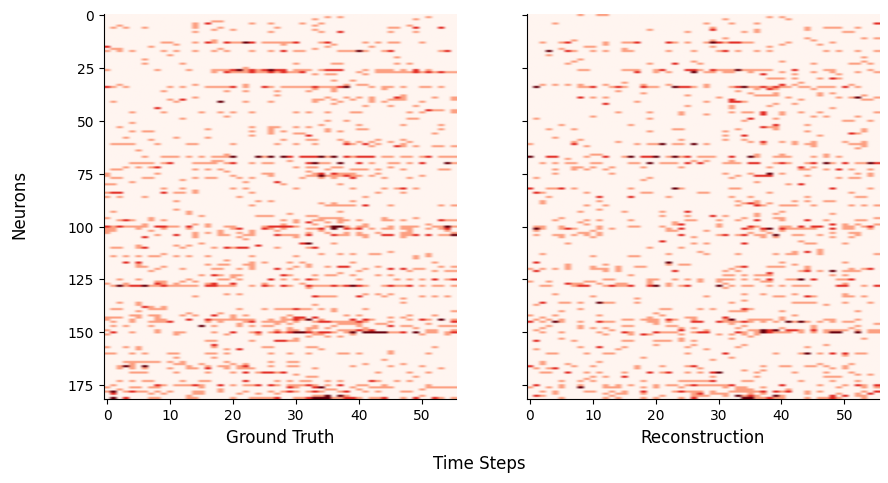

In [19]:
# heatmap of spikes 
idx = 25
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
axs[0].imshow(observations_test[idx][:, :182].T, aspect='auto', cmap='Reds', vmin=0, vmax=3)
axs[1].imshow(trajectories_test[idx][:observations_test[idx].shape[0], :182].T, aspect='auto', cmap='Reds', vmin=0, vmax=3)
axs[0].set_xlabel("Ground Truth", fontsize=FONT_SIZE)
axs[1].set_xlabel("Reconstruction", fontsize=FONT_SIZE)
for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
# common y label
fig.text(0.5, -0.02, 'Time Steps', ha='center', va='center', fontsize=FONT_SIZE)
fig.text(0.04, 0.5, 'Neurons', ha='center', va='center', rotation='vertical', fontsize=FONT_SIZE)
plt.show()
#save_fig(fig, "mc_maze_all_spikes")

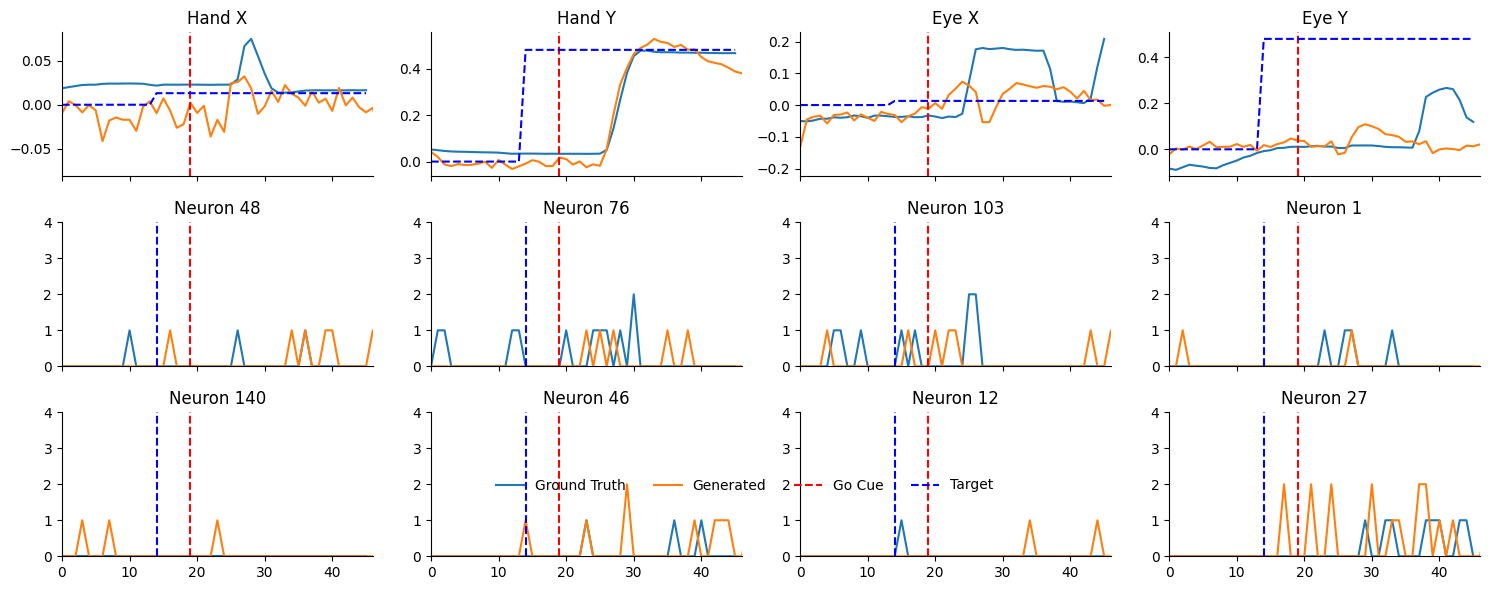

In [24]:
time_series_index = np.random.randint(len(trajectories_test))

titles = ["Hand X", "Hand Y", "Eye X", "Eye Y"]

# make a grid of subplots to plot the 4 last dimensions of the trajectories and 6 randomly selected dimensions
fig, axs = plt.subplots(3, 4, figsize=(15, 6), sharex=True)
for i in range(12):
    ax = axs[i // 4, i % 4]
    ax.set_xlim(0, observations_test[time_series_index].shape[0])
    if i < 4:
        ax.plot(observations_test[time_series_index]
                 [:, -4 + i], label='Ground Truth')
        ax.plot(trajectories_test[time_series_index]
                 [:, -4 + i], label='Generated')
        ax.axvline(np.where(externals_test[time_series_index][:, 0] == 1)[
                    0][0], color='r', linestyle='--', label='Go Cue')
        ax.plot(externals_test[time_series_index][:, i %
                 2 + 1], color='b', linestyle='--', label='Target')
        ax.set_title(f"{titles[i]}")
        handles, labels = ax.get_legend_handles_labels()
    else:
        dim = best_dims[i-4][0]
        ax.plot(observations_test[time_series_index]
                 [:, dim], label='Ground Truth')
        ax.plot(trajectories_test[time_series_index]
                 [:, dim], label='Generated')
        ax.set_ylim(0, 4)
        ax.axvline(np.where(externals_test[time_series_index][:, 0] == 1)[
                    0][0], color='r', linestyle='--')
        ax.axvline(np.where(externals_test[time_series_index][:, 1] != 0)[
                    0][0], color='b', linestyle='--')
        ax.set_title(f"Neuron {dim}")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
# common legend beneath the plots
by_label = dict(zip(labels, handles))
plt.figlegend(by_label.values(), by_label.keys(), loc='lower center',
              ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.15))
plt.tight_layout()

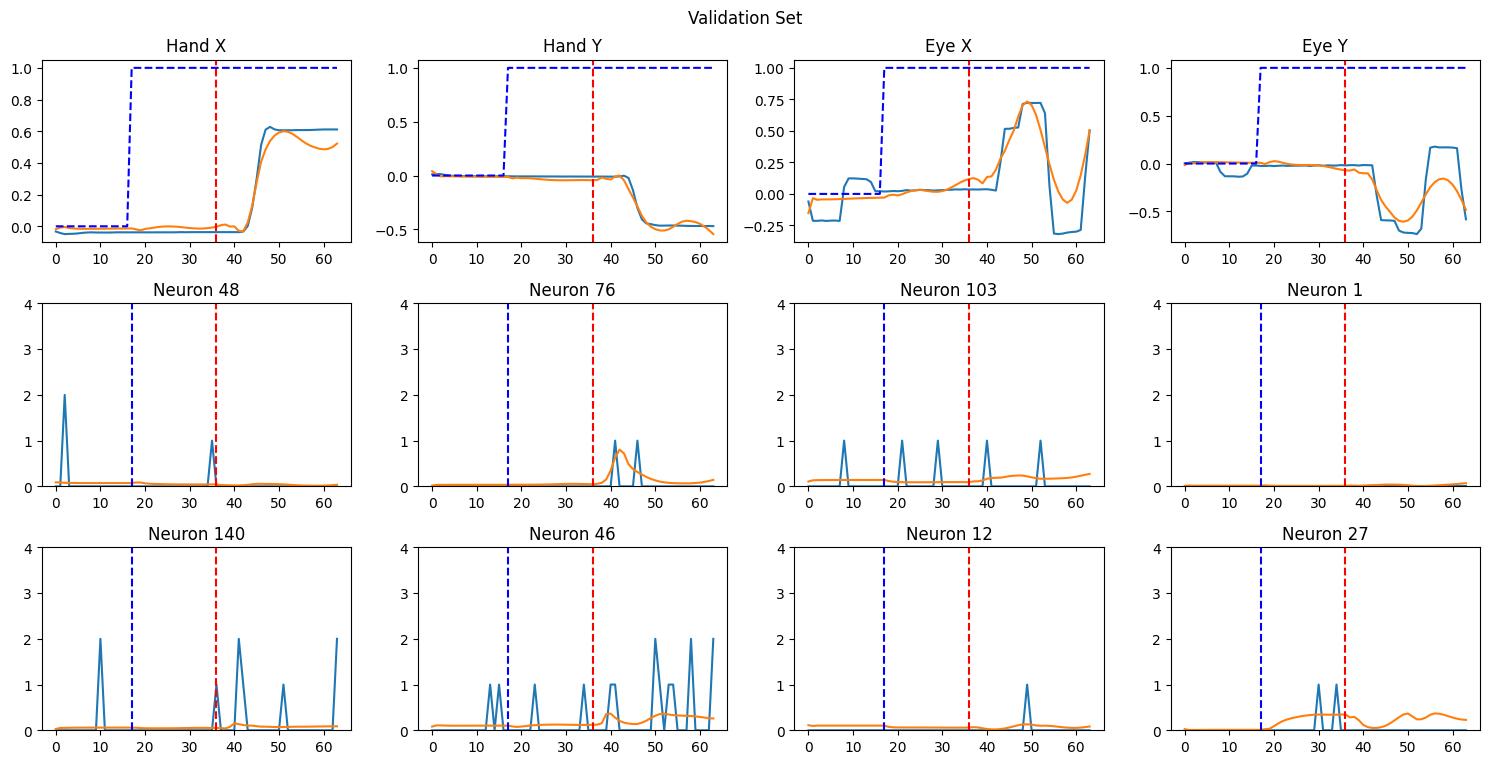

In [25]:
idx = 1
trajectory = trajectories_val[idx]
observations_val = dataset.evaluator_test_samples[idx].input
externals_val = dataset.evaluator_test_samples[idx].external

# make a grid of subplots to plot the 4 last dimensions of the trajectories and 6 randomly selected dimensions
plt.figure(figsize=(15, 10))
for i in range(12):
    plt.subplot(4, 4, i + 1)
    if i < 4:
        plt.plot(observations_val[:, -4 + i], label='Ground Truth')
        plt.plot(trajectory[:, -4 + i], label='Generated')
        plt.axvline(np.where(externals_val[:, 0] == 1)[
                    0][0], color='r', linestyle='--', label='Go Cue' if i == 0 else "")
        plt.plot(externals_val[:, i % 2 + 1] != 0, color='b',
                 linestyle='--', label='Target' if i == 0 else "")
        plt.title(f"{titles[i]}")
    else:
        dim = best_dims[i-4][0]
        plt.plot(observations_val[:, dim], label='Ground Truth')
        plt.plot(trajectory[:, dim], label='Generated')
        plt.ylim(0, 4)
        plt.axvline(np.where(externals_val[:, 0] == 1)[
                    0][0], color='r', linestyle='--')
        plt.axvline(np.where(externals_val[:, 1] != 0)[
                    0][0], color='b', linestyle='--')
        plt.title(f"Neuron {dim}")
plt.suptitle("Validation Set")
plt.tight_layout()